In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data bulanan dari rekap Project 1
data_tahunan = {
    2023: [17, 21, 25, 18, 17, 11, 14, 10, 9, 8, 7, 14],
    2024: [16, 10, 15, 20, 11, 10, 8, 11, 10, 9, 10, 24],
    2025: [14, 14, 20, 16, 30, 15, 17, 19, 13, 11, 14, 20],
    2026: [12, 22, 15, 14, 11, 13, 11, 11, 10] # Jan–Sep saja
}
bulan = ["Januari","Februari","Maret","April","Mei","Juni","Juli","Agustus","September","Oktober","November","Desember"]

rows = []
for tahun, nilai_bulanan in data_tahunan.items():
    for nomor_bulan, jumlah in enumerate(nilai_bulanan, start=1):
        rows.append({
            "Periode": pd.Timestamp(tahun, nomor_bulan, 1),
            "Tahun": tahun,
            "Bulan": nomor_bulan,
            "Jumlah Kejadian": jumlah
        })

data_sar = pd.DataFrame(rows)
data_sar.head()

,Periode,Tahun,Bulan,Jumlah Kejadian
0,2023-01-01,2023,1,17
1,2023-02-01,2023,2,21
2,2023-03-01,2023,3,25
3,2023-04-01,2023,4,18
4,2023-05-01,2023,5,17


pemeriksaan data

In [ ]:
print("Jumlah observasi:", len(data_sar))
print("Rentang periode:", data_sar["Periode"].min().strftime("%B %Y"), "hingga", data_sar["Periode"].max().strftime("%B %Y"))
print("Jumlah missing value per kolom:")
print(data_sar.isna().sum())
print("Total kejadian SAR:", data_sar["Jumlah Kejadian"].sum())

Jumlah observasi: 45
Rentang periode: January 2023 hingga September 2026
Jumlah missing value per kolom:
Periode            0
Tahun              0
Bulan              0
Jumlah Kejadian    0
dtype: int64
Total kejadian SAR: 647


Statistik deskriptif

In [ ]:
statistik = data_sar["Jumlah Kejadian"].describe()
statistik

,Jumlah Kejadian
count,45.000000
mean,14.377778
std,5.014927
min,7.000000
25%,11.000000
50%,14.000000
75%,17.000000
max,30.000000


In [ ]:
ringkasan = pd.DataFrame({
    "Statistik": ["Jumlah observasi", "Total kejadian", "Rata-rata", "Median", "Minimum", "Maksimum", "Standar deviasi (sampel)"],
    "Nilai": [
        len(data_sar),
        data_sar["Jumlah Kejadian"].sum(),
        data_sar["Jumlah Kejadian"].mean(),
        data_sar["Jumlah Kejadian"].median(),
        data_sar["Jumlah Kejadian"].min(),
        data_sar["Jumlah Kejadian"].max(),
        data_sar["Jumlah Kejadian"].std()
    ]
})
ringkasan

,Statistik,Nilai
0,Jumlah observasi,45.000000
1,Total kejadian,647.000000
2,Rata-rata,14.377778
3,Median,14.000000
4,Minimum,7.000000
5,Maksimum,30.000000
6,Standar deviasi (sampel),5.014927


Grafik time series bulanan

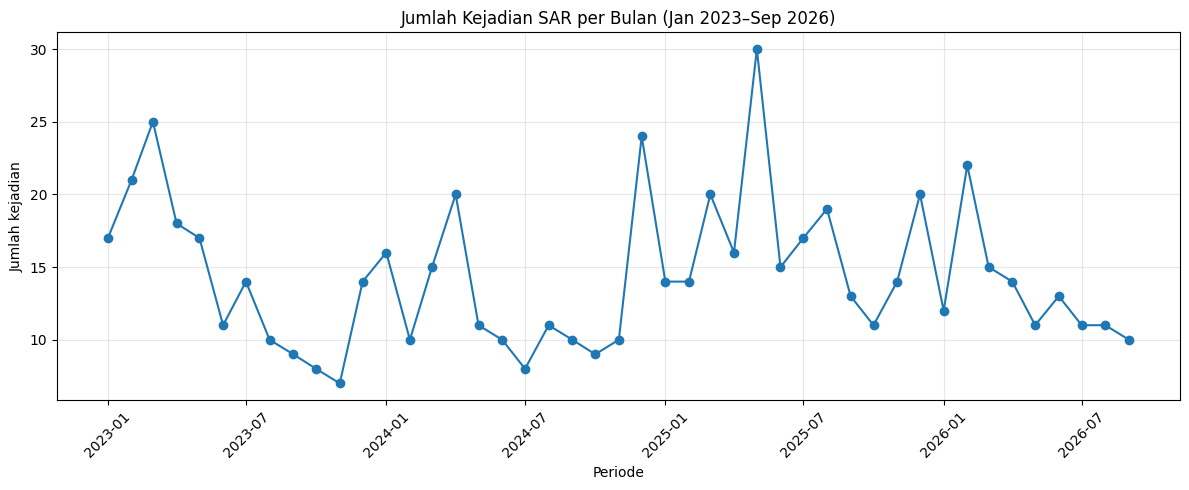

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(data_sar["Periode"], data_sar["Jumlah Kejadian"], marker="o")
plt.title("Jumlah Kejadian SAR per Bulan (Jan 2023–Sep 2026)")
plt.xlabel("Periode")
plt.ylabel("Jumlah kejadian")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Grafik time series menunjukkan perubahan jumlah kejadian SAR dari Januari 2023 hingga September 2026. Berdasarkan data yang digunakan, jumlah kejadian mengalami fluktuasi dari bulan ke bulan. Puncak jumlah kejadian tercatat sebanyak 30 kejadian pada Mei 2025, sedangkan jumlah terendah sebanyak 7 kejadian pada November 2023.

Hal ini menunjukkan bahwa jumlah kejadian SAR tidak selalu sama setiap bulannya.

Total kejadian per tahun

,Jumlah Kejadian
Tahun,
2023,171
2024,154
2025,203
2026,119


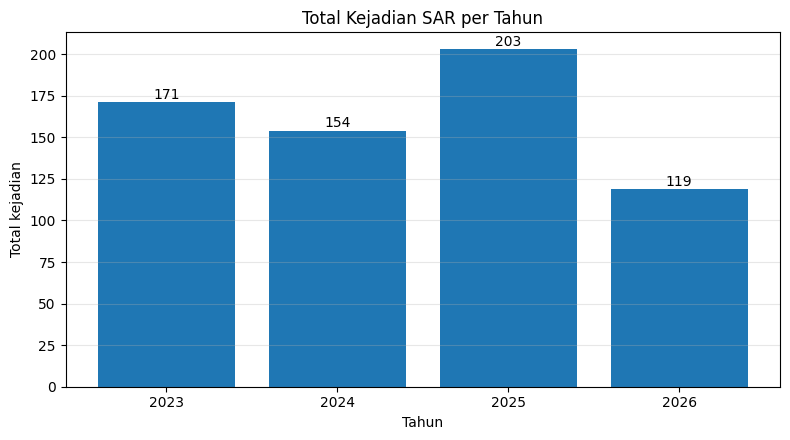

In [ ]:
total_tahunan = data_sar.groupby("Tahun")["Jumlah Kejadian"].sum()
display(total_tahunan)

plt.figure(figsize=(8, 4.5))
plt.bar(total_tahunan.index.astype(str), total_tahunan.values)
plt.title("Total Kejadian SAR per Tahun")
plt.xlabel("Tahun")
plt.ylabel("Total kejadian")
plt.grid(axis="y", alpha=0.3)
for x, y in enumerate(total_tahunan.values):
    plt.text(x, y + 2, str(y), ha="center")
plt.tight_layout()
plt.show()

Berdasarkan rekapitulasi tahunan, tahun 2025 memiliki jumlah kejadian tertinggi, yaitu 203 kejadian. Tahun 2024 mencatat 154 kejadian, sedangkan tahun 2023 sebanyak 171 kejadian. Pada tahun 2026 tercatat 119 kejadian hingga September. Angka tahun 2026 belum dapat dibandingkan secara langsung dengan total satu tahun penuh karena periode pengamatannya belum lengkap.